# Arbitrary Value Imputation

Arbitrary value imputation replaces missing values with an arbitrary, predefined number that does not naturally occur in the dataset (for example, `-1`, `999`, or `-999`). 

This technique flags missing entries by placing them far outside the normal feature distribution.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand the concept of arbitrary value imputation and how to select safe arbitrary numbers.
2. Recognize which machine learning algorithms can handle arbitrary imputation and which algorithms are distorted by it.
3. Prevent data leakage by establishing feature boundaries strictly on the training set.
4. Implement arbitrary value imputation using both **pandas** and **scikit-learn's `SimpleImputer`**.
5. Analyze the resulting distribution impact and understand its trade-offs.

---
## 1. When to Use (and When to AVOID) Arbitrary Value Imputation

### Algorithms Compatible with Arbitrary Imputation:
- **Tree-Based Models (Decision Trees, Random Forests, Gradient Boosting / XGBoost / LightGBM)**:
  - Trees make step-wise decisions (splits like `Feature <= 0`).
  - They can easily separate the arbitrary value (e.g., `LotFrontage == 999`) into its own leaf node without assuming a continuous linear trend.

### Algorithms Severely Harmed by Arbitrary Imputation:
- **Linear Models (Linear Regression, Logistic Regression)**:
  - Extreme values distort regression slope coefficients $\beta_j$ and bias predictions.
- **Distance-Based Algorithms (KNN, SVM, K-Means)**:
  - Placing a point at `999` dramatically inflates Euclidean distance $\sqrt{\sum(x_i - y_i)^2}$, overwhelming other features.
- **Neural Networks**:
  - Extreme values cause gradient explosion or saturate activation functions.

> **Rule of Thumb**: Only consider arbitrary value imputation when using tree-based ensembles, or choose a neutral non-negative indicator (like `-1` for strictly positive variables).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Matplotlib configuration
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We use numerical features from the Ames House Prices dataset. We perform the train/test split **before** examining the range of the features to avoid data leakage.

In [2]:
cols_to_use = [
    "OverallQual",
    "TotalBsmtSF",
    "1stFlrSF",
    "GrLivArea",
    "LotFrontage",
    "MasVnrArea",
    "GarageYrBlt",
    "SalePrice",
]

data_path = '../datasets/houseprice.csv'
if not os.path.exists(data_path):
    data_path = 'https://raw.githubusercontent.com/cmps460s26/cmps460-content/refs/heads/main/examples/03.dp/datasets/houseprice.csv'

data = pd.read_csv(data_path, usecols=cols_to_use)

# Split into predictors and target
X = data.drop("SalePrice", axis=1)
y = data["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (1022, 7)
X_test shape:  (438, 7)


---
## 3. Determining Appropriate Arbitrary Values

To pick an arbitrary value that does not overlap with real observations, we examine the minimum and maximum values of the training set.

In [3]:
# Check variables with missing values in X_train
vars_to_impute = [col for col in X_train.columns if X_train[col].isnull().sum() > 0]

# Inspect min, max, and current range on X_train
stats = X_train[vars_to_impute].agg(['min', 'max', 'mean'])
stats

,LotFrontage,MasVnrArea,GarageYrBlt
min,21.000000,0.000000,1900.000000
max,313.000000,1600.000000,2010.000000
mean,69.668667,103.553589,1978.012397


### Selecting Arbitrary Values:
- **`LotFrontage`**: Ranges from $21$ to $313$. A value of `999` or `-1` is well outside the observed range.
- **`MasVnrArea`**: Ranges from $0$ to $1600$. A value of `9999` or `-1` works.
- **`GarageYrBlt`**: Represents calendar years ($1900$ to $2010$). Choosing `1800` or `-1` clearly marks missingness without overlapping valid building years.

---
## 4. Method 1: Imputation Using Pandas

We construct a dictionary of arbitrary values learned from `X_train` and apply it to both `X_train` and `X_test`.

In [4]:
# Define arbitrary values well outside the observed training distributions
imputation_dict = {
    'LotFrontage': 999,
    'MasVnrArea': 999,
    'GarageYrBlt': 1800,
}

print("Selected Imputation Values:")
for col, val in imputation_dict.items():
    print(f"  {col}: {val}")

Selected Imputation Values:
  LotFrontage: 999
  MasVnrArea: 999
  GarageYrBlt: 1800


In [5]:
# Create copies for pandas implementation
X_train_pd = X_train.copy()
X_test_pd = X_test.copy()

# Impute missing values
X_train_pd.fillna(imputation_dict, inplace=True)
X_test_pd.fillna(imputation_dict, inplace=True)

# Verify 0 remaining nulls
print(f"Nulls in X_train after imputation: {X_train_pd[vars_to_impute].isnull().sum().to_dict()}")
print(f"Nulls in X_test after imputation:  {X_test_pd[vars_to_impute].isnull().sum().to_dict()}")

Nulls in X_train after imputation: {'LotFrontage': 0, 'MasVnrArea': 0, 'GarageYrBlt': 0}
Nulls in X_test after imputation:  {'LotFrontage': 0, 'MasVnrArea': 0, 'GarageYrBlt': 0}


---
## 5. Method 2: Imputation Using Scikit-Learn `SimpleImputer`

With scikit-learn, we use `SimpleImputer(strategy='constant', fill_value=...)`. 

When different features require different arbitrary values, we can configure a `SimpleImputer` for each column or apply a uniform marker like `-1` for strictly positive variables.

In [6]:
# Using -1 as a uniform arbitrary value for non-negative numerical features
imputer_neg1 = SimpleImputer(strategy='constant', fill_value=-1)
imputer_neg1.set_output(transform="pandas")

# Fit and transform
imputer_neg1.fit(X_train[vars_to_impute])

X_train_sk = X_train.copy()
X_test_sk = X_test.copy()

X_train_sk[vars_to_impute] = imputer_neg1.transform(X_train[vars_to_impute])
X_test_sk[vars_to_impute] = imputer_neg1.transform(X_test[vars_to_impute])

# Verify transformed values
X_train_sk[vars_to_impute].describe().round(1)

,LotFrontage,MasVnrArea,GarageYrBlt
count,1022.0,1022.0,1022.0
mean,56.6,103.0,1873.4
std,34.5,181.3,443.6
min,-1.0,-1.0,-1.0
25%,41.0,0.0,1958.0
50%,62.0,0.0,1977.0
75%,79.0,170.0,2001.0
max,313.0,1600.0,2010.0


---
## 6. Evaluating the Impact on Feature Distributions

Let's visualize how arbitrary value imputation affects the histogram of `LotFrontage`.

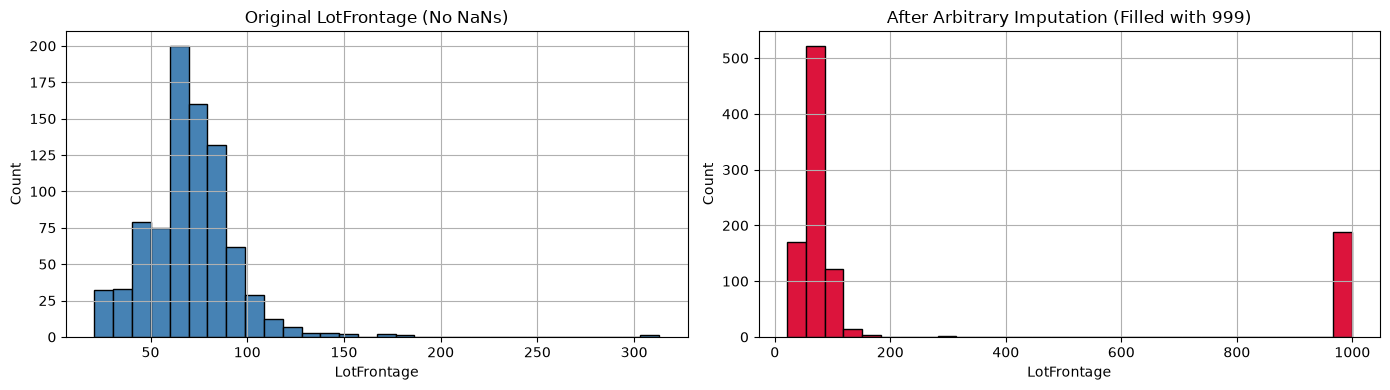

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Original distribution (ignoring NaNs)
X_train['LotFrontage'].dropna().hist(bins=30, ax=ax1, color='steelblue', edgecolor='black')
ax1.set_title('Original LotFrontage (No NaNs)')
ax1.set_xlabel('LotFrontage')
ax1.set_ylabel('Count')

# After Arbitrary Imputation (999)
X_train_pd['LotFrontage'].hist(bins=30, ax=ax2, color='crimson', edgecolor='black')
ax2.set_title('After Arbitrary Imputation (Filled with 999)')
ax2.set_xlabel('LotFrontage')
ax2.set_ylabel('Count')

plt.tight_layout()
plt.show()

### Key Insights from the Visualization:
1. **Isolated Cluster**: The missing values now form an isolated cluster at `999`. 
2. **Decision Tree Friendly**: A decision tree split at `LotFrontage > 500` cleanly routes all missing records down one branch.
3. **Linear Model Disaster**: In a linear model $y = \beta x$, this single feature at 999 would produce wildly distorted predictions!

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **Model Compatibility** | Excellent for **Tree-based models** (Random Forest, XGBoost). Never use with **Linear Regression**, **SVM**, or **KNN**. |
| **Value Choice** | Must be distinctly outside the natural domain (e.g. `-1` for positive values, `999` for bounded measurements). |
| **Data Leakage** | Bounds must be checked on `X_train` only. Ensure the chosen arbitrary value is never a valid test observation. |
| **Alternatives** | Consider **Median Imputation + Missing Indicator** (Notebook 05) as a safer, algorithm-agnostic alternative. |
